<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070e-xyz-three-ansatze.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070e. VQE for the XYZ chain with three ansätze

The variational quantum eigensolver (VQE) prepares a trial state $|\psi(\boldsymbol\theta)\rangle$ with a circuit of adjustable angles $\boldsymbol\theta$ and lowers its energy by changing the angles [1, 2]. The set of states that one circuit layout can prepare is the ansatz, and the ansatz decides which states the training can reach at all. We study this on a spin chain without any conserved magnetisation, the open XYZ chain of $N=8$ qubits in a transverse and a longitudinal field, whose ground state we obtain exactly by diagonalising its $256\times256$ Hamiltonian.

We compare three ansätze with four layers each. The hardware-efficient ansatz (HEA) uses single-qubit rotations and controlled-$Z$ gates [3]. The Hamiltonian-variational ansatz (HVA) is built from exponentials of the terms of the Hamiltonian, with one set of angles shared by all gates of a layer [4]. The HVA with free angles uses the same gates, each with its own angles. We train all three with exact energies and exact gradients and follow the energy error, the fidelity with the exact ground state and three observables during training. The shared-angle HVA, which has the fewest angles and the most physical structure, never acquires any overlap with the ground state. The reason is a mirror symmetry of its gates, and the general lesson is that an ansatz must reach the symmetry sector of the target state.

All results are exact state-vector simulations, so energies and gradients are computed without shot noise. On a device the energy would be estimated from measured bit strings and the gradient by the parameter-shift rule. Sections 1 to 7 form the classroom route. They train every ansatz from one random start and run in well under a minute on a laptop CPU. Section 8 repeats the training with three random starts per ansatz, as in the figures of the lecture, and adds about half a minute. Section 9 lists exercises for home.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, on the CPU. JAX applies the gates, computes the gradients and runs the training loops, NumPy builds the Hamiltonian and the exact references, and Matplotlib draws the figures. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # small calculations, never the GPU
import json, re, time
from pathlib import Path
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

jax.config.update("jax_enable_x64", True)
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
NAVY, BLUE, ORANGE, GRAY, GREEN = "#002B5C", "#3E8FD0", "#D35A05", "#5A6270", "#1B7F36"
COL = {"HEA": NAVY, "HVA": ORANGE, "HVA, free angles": GREEN}     # same colours as the lecture figures
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "xtick.labelsize": 12, "ytick.labelsize": 12,
                     "legend.fontsize": 11, "figure.figsize": (4.8, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight", "pdf.fonttype": 42, "ps.fonttype": 42})
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)
started = time.perf_counter()
RESULTS = {}
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The XYZ chain in two fields

Each qubit is a spin one-half, and neighbouring spins interact along all three axes with different strengths. A uniform field acts along $x$ and along $z$. The Hamiltonian of the open chain is
$$\hat{\mathcal H}=\sum_{i=0}^{N-2}\big(J_x\hat X_i\hat X_{i+1}+J_y\hat Y_i\hat Y_{i+1}+J_z\hat Z_i\hat Z_{i+1}\big)+\sum_{i=0}^{N-1}\big(h_x\hat X_i+h_z\hat Z_i\big) , \tag{1}$$
where $\hat X_i$, $\hat Y_i$ and $\hat Z_i$ are the Pauli operators of qubit $i$. We take $J_x=1$, $J_y=0.7$, $J_z=0.4$, $h_x=1$ and $h_z=0.5$. All couplings are positive, so neighbouring spins prefer to point in opposite directions, while the fields pull every spin towards $-x$ and $-z$. With three different couplings and two fields, neither the magnetisation $\sum_i\hat Z_i$ nor the parity $\prod_i\hat X_i$ commutes with $\hat{\mathcal H}$, so the chain has none of the symmetries that the ansätze of the earlier VQE examples were built to respect.

The exact ground state $|\psi_0\rangle$ with energy $E_0$, the first excited energy $E_1$ and the gap $\Delta E=E_1-E_0$ follow from dense diagonalisation. Besides the energy we follow three properties of a state, each with a direct meaning. The transverse magnetisation and the nearest-neighbour correlation along $x$,
$$m_x=\frac1N\sum_{i=0}^{N-1}\langle\hat X_i\rangle ,\qquad C_{xx}=\frac1{N-1}\sum_{i=0}^{N-2}\langle\hat X_i\hat X_{i+1}\rangle , \tag{2}$$
are local quantities that a device estimates from bit strings measured after a Hadamard gate on every qubit. The half-chain entanglement entropy $S_{\rm vN}$, in bits, measures how strongly the left four qubits are entangled with the right four, and it is computed from the Schmidt coefficients of that cut. The quality of a trial state is measured by its fidelity with the exact ground state,
$$F=|\langle\psi_0|\psi(\boldsymbol\theta)\rangle|^2 , \tag{3}$$
the probability that a measurement in the eigenbasis of $\hat{\mathcal H}$ would find the trial state in the ground state.

In [2]:
N, L = 8, 4
Jx, Jy, Jz, hx, hz = 1.0, 0.7, 0.4, 1.0, 0.5
I2 = np.eye(2); X = np.array([[0, 1], [1, 0]], complex); Y = np.array([[0, -1j], [1j, 0]]); Z = np.diag([1.0 + 0j, -1.0])

def op(single, i):
    # single-qubit operator on qubit i; qubit 0 is the leftmost Kronecker factor (most significant bit)
    out = np.array([[1.0 + 0j]])
    for q in range(N):
        out = np.kron(out, single if q == i else I2)
    return out

Xs = [op(X, i) for i in range(N)]; Ys = [op(Y, i) for i in range(N)]; Zs = [op(Z, i) for i in range(N)]
H = sum(Jx * Xs[i] @ Xs[i + 1] + Jy * Ys[i] @ Ys[i + 1] + Jz * Zs[i] @ Zs[i + 1] for i in range(N - 1))
H = H + sum(hx * Xs[i] + hz * Zs[i] for i in range(N))                        # equation (1)
assert np.allclose(H, H.conj().T)
evals, evecs = np.linalg.eigh(H)
E0, E1, gs = evals[0], evals[1], evecs[:, 0]
MX = sum(Xs) / N                                                             # equation (2)
CXX = sum(Xs[i] @ Xs[i + 1] for i in range(N - 1)) / (N - 1)
MAG, PAR = sum(Zs), np.linalg.multi_dot(Xs)
print("[H, sum Z] and [H, prod X] nonzero:", np.abs(H @ MAG - MAG @ H).max() > 0.1, np.abs(H @ PAR - PAR @ H).max() > 0.1)

def entropy_bits(psi):
    s = np.linalg.svd(np.asarray(psi).reshape(2 ** (N // 2), -1), compute_uv=False) ** 2
    s = s[s > 1e-14]
    return float(-(s * np.log2(s)).sum())

def ev(O, psi):
    return float(np.real(np.conj(psi) @ (O @ psi)))

exact = dict(mx=ev(MX, gs), cxx=ev(CXX, gs), S=entropy_bits(gs))
assert abs(ev(H, gs) - E0) < TOL
print(f"E0 = {E0:.4f}, E1 = {E1:.4f}, gap = {E1 - E0:.4f}")
print(f"exact m_x = {exact['mx']:.4f}, C_xx = {exact['cxx']:.4f}, S_vN = {exact['S']:.4f} bits")
RESULTS["exact"] = dict(E0=E0, E1=E1, gap=E1 - E0, **exact)

[H, sum Z] and [H, prod X] nonzero: True True
E0 = -10.6453, E1 = -9.6847, gap = 0.9606
exact m_x = -0.2031, C_xx = -0.6070, S_vN = 1.0243 bits


The ground state has a negative transverse magnetisation, as the field term $h_x\sum_i\hat X_i$ favours $\langle\hat X_i\rangle<0$, and negative correlations $C_{xx}$, as the coupling $J_x>0$ favours opposite neighbours. Its half-chain entropy is about one bit, so a product state cannot represent it and the circuit has to build entanglement across the middle of the chain. The gap of about one sets the energy scale below which a trial state must lie to be close to the ground state.

## 3. The state-vector simulator

We store a state of $N$ qubits as a vector of $2^N$ amplitudes and reshape it into a tensor with one index of size two per qubit when a gate acts. A one-qubit gate, a $2\times2$ matrix, is contracted with the index of its qubit, and a two-qubit gate on neighbours $(q,q+1)$, a $4\times4$ matrix, with the two indices of the pair. This costs of order $2^N$ operations per gate instead of the $4^N$ of a full matrix. The cell checks both contractions once against the Kronecker-product matrices.

In [3]:
def apply_1q(psi, U, q):
    t = jnp.moveaxis(jnp.tensordot(U, psi.reshape((2,) * N), axes=([1], [q])), 0, q)
    return t.reshape(-1)

def apply_2q(psi, U4, q):
    t = jnp.tensordot(U4.reshape(2, 2, 2, 2), psi.reshape((2,) * N), axes=([2, 3], [q, q + 1]))
    return jnp.moveaxis(t, (0, 1), (q, q + 1)).reshape(-1)

rng = np.random.default_rng(11)
v = rng.normal(size=2 ** N) + 1j * rng.normal(size=2 ** N); v /= np.linalg.norm(v)
U2 = np.linalg.qr(rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)))[0]
U4 = np.linalg.qr(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))[0]
full2 = np.kron(np.kron(np.eye(2 ** 3), U2), np.eye(2 ** 4))             # U2 on qubit 3
full4 = np.kron(np.kron(np.eye(2 ** 2), U4), np.eye(2 ** 4))             # U4 on qubits (2, 3)
assert np.allclose(np.asarray(apply_1q(jnp.asarray(v), jnp.asarray(U2), 3)), full2 @ v, atol=TOL)
assert np.allclose(np.asarray(apply_2q(jnp.asarray(v), jnp.asarray(U4), 2)), full4 @ v, atol=TOL)
print("tensor contractions agree with the Kronecker-product matrices")

tensor contractions agree with the Kronecker-product matrices


## 4. Three ansätze

All three circuits have $L=4$ layers. The rotations are $\hat R_y(\theta)=e^{-i\theta\hat Y/2}$ and $\hat R_z(\theta)=e^{-i\theta\hat Z/2}$, and every exponential of a Pauli string $\hat P$ is evaluated as $e^{-ia\hat P}=\cos a\,\hat I-i\sin a\,\hat P$.

The HEA starts from $|0\dots0\rangle$, and each of its layers applies $\hat R_z\hat R_y$ with independent angles to every qubit and then a chain of $\widehat{\rm CZ}$ gates on all neighbouring pairs. A final block of rotations closes the circuit, so the HEA has $n=2N(L+1)=80$ angles. Its gates are those that a device offers natively, and they know nothing about the Hamiltonian.

Each layer of the HVA follows the structure of equation (1). A two-qubit gate
$$\hat G(a,b,c)=e^{-i(a\hat X\hat X+b\hat Y\hat Y+c\hat Z\hat Z)} \tag{4}$$
acts first on the even bonds $(0,1),(2,3),(4,5),(6,7)$ and then on the odd bonds $(1,2),(3,4),(5,6)$, and a one-qubit gate $e^{-i(\beta\hat X+\delta\hat Z)}$ follows on every qubit. The three terms of (4) commute with each other, so $\hat G$ is the product of three exponentials. All even bonds of a layer share one triple $(a,b,c)$, all odd bonds share another, and all qubits share $(\beta,\delta)$, which gives eight angles per layer and $n=32$ in total. The circuit starts from the product ground state of the field term $h_x\hat X_i+h_z\hat Z_i$ on every qubit.

The HVA with free angles has the gates and the start of the HVA, but every gate carries its own angles, $3(N-1)$ per layer for the bonds and $2N$ for the fields, which gives $n=148$.

The figure shows one HVA layer. The dashed line marks the middle of the chain, which will matter in Section 7.

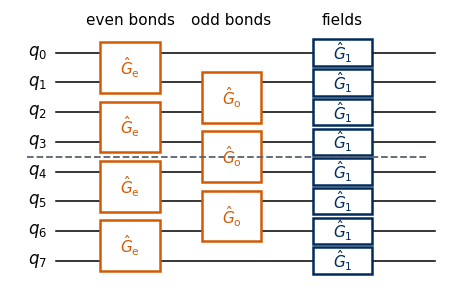

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 3.6))
ys = (N - 1 - np.arange(N)) * 0.45
for q, y in enumerate(ys):
    ax.plot([0.2, 4.3], [y, y], color="black", lw=1.1, zorder=0)
    ax.text(0.1, y, f"$q_{q}$", ha="right", va="center", fontsize=12)
def box(x, q0, q1, label, c):
    pad = 0.16 if q1 > q0 else 0.2
    y0, y1 = ys[q1] - pad, ys[q0] + pad
    ax.add_patch(Rectangle((x - 0.32, y0), 0.64, y1 - y0, fc="white", ec=c, lw=1.8, zorder=2))
    ax.text(x, (y0 + y1) / 2, label, ha="center", va="center", fontsize=11, color=c, zorder=3)
for q in range(0, N - 1, 2):
    box(1.0, q, q + 1, r"$\hat G_{\rm e}$", ORANGE)
for q in range(1, N - 1, 2):
    box(2.1, q, q + 1, r"$\hat G_{\rm o}$", ORANGE)
for q in range(N):
    box(3.3, q, q, r"$\hat G_1$", NAVY)
ax.axhline((ys[3] + ys[4]) / 2, color=GRAY, ls="--", lw=1.3, xmin=0.04, xmax=0.96)
ax.text(1.0, ys[0] + 0.42, "even bonds", ha="center", fontsize=11)
ax.text(2.1, ys[0] + 0.42, "odd bonds", ha="center", fontsize=11)
ax.text(3.3, ys[0] + 0.42, "fields", ha="center", fontsize=11)
ax.set_xlim(-0.3, 4.4); ax.set_ylim(-0.4, ys[0] + 0.65); ax.axis("off")
save(fig, "fig_lab070e_hva_layer"); plt.show()

In the shared-angle HVA every orange box of a column carries the same gate, $\hat G_{\rm e}=\hat G(a_{\rm e},b_{\rm e},c_{\rm e})$ on the even bonds and $\hat G_{\rm o}=\hat G(a_{\rm o},b_{\rm o},c_{\rm o})$ on the odd bonds, and every navy box carries $\hat G_1=e^{-i(\beta\hat X+\delta\hat Z)}$. Reflected at the dashed line, the pattern of boxes is mapped onto itself. In the HVA with free angles each box has its own angles. The cell implements the three circuits and counts their angles.

In [5]:
XXm, YYm, ZZm = (jnp.array(np.kron(P, P)) for P in (X, Y, Z))
Xm, Zm = jnp.array(X), jnp.array(Z)
I4 = jnp.eye(4, dtype=jnp.complex128); I2j = jnp.eye(2, dtype=jnp.complex128)

def g2(a, b, c):        # equation (4); the three terms commute
    return ((jnp.cos(a) * I4 - 1j * jnp.sin(a) * XXm) @ (jnp.cos(b) * I4 - 1j * jnp.sin(b) * YYm)
            @ (jnp.cos(c) * I4 - 1j * jnp.sin(c) * ZZm))

def g1(beta, delta):    # exp(-i(beta X + delta Z)) = cos r I - i sin r (beta X + delta Z)/r
    r = jnp.sqrt(beta ** 2 + delta ** 2 + 1e-30)
    return jnp.cos(r) * I2j - 1j * jnp.sin(r) * (beta * Xm + delta * Zm) / r

def ry(a):
    c, s = jnp.cos(a / 2), jnp.sin(a / 2)
    return jnp.array([[c, -s], [s, c]], dtype=jnp.complex128)

def rz(a):
    return jnp.array([[jnp.exp(-0.5j * a), 0], [0, jnp.exp(0.5j * a)]])

from scipy.linalg import expm
a, b, c = 0.3, -0.7, 1.1
assert np.allclose(np.asarray(g2(a, b, c)), expm(-1j * (a * np.kron(X, X) + b * np.kron(Y, Y) + c * np.kron(Z, Z))), atol=TOL)
assert np.allclose(np.asarray(g1(0.4, -0.9)), expm(-1j * (0.4 * X - 0.9 * Z)), atol=TOL)

idx = np.arange(2 ** N)
BITS = (idx[:, None] >> (N - 1 - np.arange(N))) & 1          # BITS[i, q] = b_q of basis state i
czdiag = jnp.array(np.prod([np.where(BITS[:, i] & BITS[:, i + 1], -1.0, 1.0) for i in range(N - 1)], axis=0))

w1, v1 = np.linalg.eigh(hx * X + hz * Z)                      # ground state of the field term on one qubit
prod = v1[:, 0]
for _ in range(N - 1):
    prod = np.kron(prod, v1[:, 0])
prod = jnp.array(prod)
zero = jnp.zeros(2 ** N, dtype=jnp.complex128).at[0].set(1.0)
even, odd = list(range(0, N - 1, 2)), list(range(1, N - 1, 2))

def state_hea(th):                      # th has shape (L+1, N, 2): angles of R_y and R_z
    psi = zero
    for l in range(L + 1):
        for q in range(N):
            psi = apply_1q(psi, rz(th[l, q, 1]) @ ry(th[l, q, 0]), q)
        if l < L:
            psi = czdiag * psi           # the CZ chain is diagonal in the computational basis
    return psi

def state_hva(th):                      # th has shape (L, 8): (a, b, c) even, (a, b, c) odd, beta, delta
    psi = prod
    for l in range(L):
        Ge, Go = g2(*th[l, 0:3]), g2(*th[l, 3:6])
        for q in even:
            psi = apply_2q(psi, Ge, q)
        for q in odd:
            psi = apply_2q(psi, Go, q)
        G1 = g1(th[l, 6], th[l, 7])
        for q in range(N):
            psi = apply_1q(psi, G1, q)
    return psi

def state_free(th):                     # th = (bond angles (L, N-1, 3), field angles (L, N, 2))
    bonds, fields = th
    psi = prod
    for l in range(L):
        for q in even + odd:
            psi = apply_2q(psi, g2(*bonds[l, q]), q)
        for q in range(N):
            psi = apply_1q(psi, g1(fields[l, q, 0], fields[l, q, 1]), q)
    return psi

def init(name, rng):
    # small random angles around zero; the order of the draws fixes the seeds of the lecture figures
    if name == "HEA":
        return jnp.array(rng.normal(0, 0.1, (L + 1, N, 2)))
    if name == "HVA":
        return jnp.array(rng.normal(0, 0.1, (L, 8)))
    return (jnp.array(rng.normal(0, 0.1, (L, N - 1, 3))), jnp.array(rng.normal(0, 0.1, (L, N, 2))))

STATE = {"HEA": state_hea, "HVA": state_hva, "HVA, free angles": state_free}
NPARAM = {name: sum(int(np.size(x)) for x in jax.tree_util.tree_leaves(init(name, np.random.default_rng(0)))) for name in STATE}
assert NPARAM == {"HEA": 2 * N * (L + 1), "HVA": 8 * L, "HVA, free angles": L * (3 * (N - 1) + 2 * N)}
for name, sf in STATE.items():
    assert abs(np.linalg.norm(np.asarray(sf(init(name, np.random.default_rng(1))))) - 1) < TOL
print("number of angles n:", NPARAM)

number of angles n: {'HEA': 80, 'HVA': 32, 'HVA, free angles': 148}


## 5. Training with exact gradients

The cost is the energy $E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat{\mathcal H}|\psi(\boldsymbol\theta)\rangle$, which by the variational principle is never below $E_0$. Its exact gradient comes from `jax.grad`, and the Adam optimiser [5], written out in a few lines, updates the angles with learning rate $0.02$. We call one Adam update an epoch. Before every update we record the energy, the observables (2), the fidelity (3), the Schmidt coefficients of the half-chain cut and, for Section 7, the expectation value of a reflection operator $\hat R$. The whole training of 1200 epochs runs inside one compiled loop (`lax.scan`).

In the classroom route every ansatz is trained once, from the random start with seed 0. The relative energy error $(E-E_0)/|E_0|$ and the fidelity show how far each trained state is from the ground state.

HEA               n =  80: (E - E0)/|E0| = 9.8e-03,  F = 0.9676


HVA               n =  32: (E - E0)/|E0| = 1.5e-01,  F = 0.0000


HVA, free angles  n = 148: (E - E0)/|E0| = 7.8e-04,  F = 0.9981
three trainings: 22.3 s


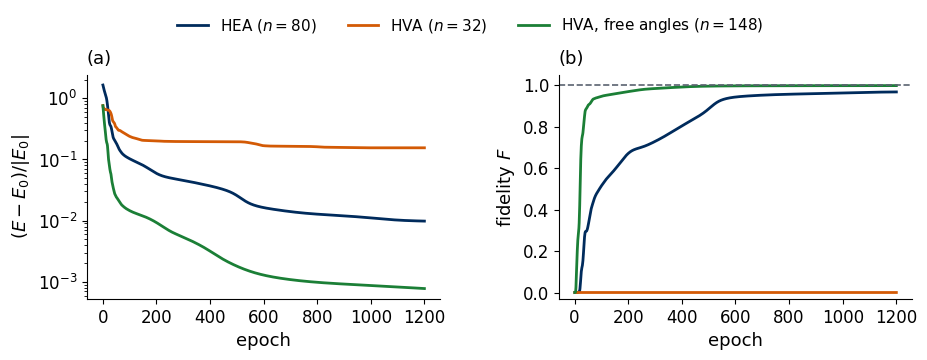

In [6]:
# reflection i -> N-1-i: the basis state b_0 ... b_{N-1} goes to b_{N-1} ... b_0 (used in Section 7)
ridx = (BITS[:, ::-1] * 2 ** (N - 1 - np.arange(N))).sum(1)
R = np.zeros((2 ** N, 2 ** N)); R[ridx, idx] = 1
Hj, gsj, MXj, CXXj, Rj = (jnp.array(A) for A in (H, gs, MX, CXX, R))
tmap = jax.tree_util.tree_map
STEPS, LR = 1200, 0.02

def make_trainer(sf, steps=STEPS, lr=LR, b1=0.9, b2=0.999, eps=1e-8):
    energy = lambda th: jnp.real(jnp.conj(sf(th)) @ (Hj @ sf(th)))
    grad = jax.grad(energy)
    def step(carry, t):
        th, m, v = carry
        p = sf(th)
        exp = lambda O: jnp.real(jnp.conj(p) @ (O @ p))
        rec = jnp.stack([exp(Hj), exp(MXj), exp(CXXj), jnp.abs(jnp.vdot(gsj, p)) ** 2, exp(Rj)])
        schmidt = jnp.linalg.svd(p.reshape(2 ** (N // 2), -1), compute_uv=False)
        g = grad(th)
        m = tmap(lambda a, b: b1 * a + (1 - b1) * b, m, g)                 # running mean of the gradient
        v = tmap(lambda a, b: b2 * a + (1 - b2) * b ** 2, v, g)            # running mean of its square
        th = tmap(lambda p_, a, b: p_ - lr * (a / (1 - b1 ** t)) / (jnp.sqrt(b / (1 - b2 ** t)) + eps), th, m, v)
        return (th, m, v), (rec, schmidt)
    def run(th):
        z = tmap(jnp.zeros_like, th)
        (th, _, _), (rec, schmidt) = lax.scan(step, (th, z, z), jnp.arange(1, steps + 1, dtype=jnp.float64))
        return th, rec, schmidt
    return jax.jit(run)

def history(rec, schmidt):
    # columns: E, m_x, C_xx, F, <R>, S_vN (bits), recorded before every Adam update
    lam = np.asarray(schmidt) ** 2
    S = -np.sum(np.where(lam > 1e-14, lam * np.log2(np.where(lam > 1e-14, lam, 1.0)), 0.0), axis=1)
    return np.column_stack([np.asarray(rec), S])

TRAINERS = {name: make_trainer(sf) for name, sf in STATE.items()}
t0 = time.perf_counter()
CLASS = {}
for name in STATE:
    th, rec, sch = TRAINERS[name](init(name, np.random.default_rng(0)))
    CLASS[name] = dict(theta=th, hist=history(rec, sch))
    h = CLASS[name]["hist"]
    assert np.all(h[:, 0] >= E0 - TOL)                                   # variational principle
    print(f"{name:17s} n = {NPARAM[name]:3d}: (E - E0)/|E0| = {(h[-1, 0] - E0) / abs(E0):.1e},  F = {h[-1, 3]:.4f}")
t_class = time.perf_counter() - t0
print(f"three trainings: {t_class:.1f} s")
RESULTS["classroom_seed0"] = {name: dict(n=NPARAM[name], rel_err=(d["hist"][-1, 0] - E0) / abs(E0), F=d["hist"][-1, 3],
                                         mx=d["hist"][-1, 1], cxx=d["hist"][-1, 2], S=d["hist"][-1, 5]) for name, d in CLASS.items()}

def plot_training(runs, name_fig):
    ep = np.arange(1, STEPS + 1)
    fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.4))
    for name, h in runs.items():
        axs[0].semilogy(ep, (h[:, 0] - E0) / abs(E0), color=COL[name], lw=2, label=f"{name} ($n={NPARAM[name]}$)")
        axs[1].plot(ep, h[:, 3], color=COL[name], lw=2)
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel(r"$(E-E_0)/|E_0|$")
    axs[1].axhline(1, color=GRAY, ls="--", lw=1.2)
    axs[1].set_xlabel("epoch"); axs[1].set_ylabel(r"fidelity $F$"); axs[1].set_ylim(-0.03, 1.05)
    fig.legend(*axs[0].get_legend_handles_labels(), frameon=False, fontsize=11, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
    for a, letter in zip(axs, "ab"):
        a.text(0.0, 1.03, f"({letter})", transform=a.transAxes, ha="left", va="bottom")
    fig.tight_layout(w_pad=2.0); save(fig, name_fig); plt.show()

plot_training({name: d["hist"] for name, d in CLASS.items()}, "fig_lab070e_training")

Panel (a) shows the relative energy error on a logarithmic scale and panel (b) the fidelity, both against the epoch. The HVA with free angles reaches the lowest energy error and a fidelity close to one. The HEA, with about half as many angles, ends with a larger energy error and a fidelity a few percent below one. The shared-angle HVA, with the fewest angles, stops at an energy error of order ten percent, and its fidelity stays at zero during the whole run. A circuit that is too short would give a small but finite fidelity, so a fidelity that is zero at every epoch points to a property of the ansatz itself, which Section 7 identifies.

## 6. Observables during training

The energy is one number. The observables (2) and the entropy show which features of the ground state a trial state has acquired and which it still lacks. The figure follows them during the same three runs, with the exact values as dashed lines.

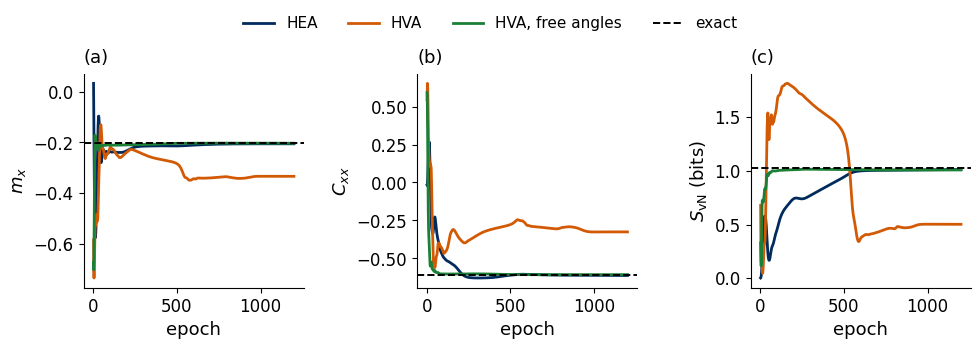

HEA               m_x = -0.2055  C_xx = -0.6134  S_vN = 1.0124   (exact -0.2031, -0.6070, 1.0243)
HVA               m_x = -0.3340  C_xx = -0.3259  S_vN = 0.5021   (exact -0.2031, -0.6070, 1.0243)
HVA, free angles  m_x = -0.2032  C_xx = -0.6078  S_vN = 1.0081   (exact -0.2031, -0.6070, 1.0243)


In [7]:
def plot_observables(runs, name_fig):
    ep = np.arange(1, STEPS + 1)
    fig, axs = plt.subplots(1, 3, figsize=(10.0, 3.3))
    for ax, k, key, lab in ((axs[0], 1, "mx", r"$m_x$"), (axs[1], 2, "cxx", r"$C_{xx}$"), (axs[2], 5, "S", r"$S_{\rm vN}$ (bits)")):
        for name, h in runs.items():
            ax.plot(ep, h[:, k], color=COL[name], lw=2, label=name)
        ax.axhline(exact[key], color="black", ls="--", lw=1.4, label="exact")
        ax.set_xlabel("epoch"); ax.set_ylabel(lab)
    for a, letter in zip(axs, "abc"):
        a.text(0.0, 1.03, f"({letter})", transform=a.transAxes, ha="left", va="bottom")
    fig.legend(*axs[0].get_legend_handles_labels(), frameon=False, fontsize=11, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.08))
    fig.tight_layout(w_pad=1.5); save(fig, name_fig); plt.show()

plot_observables({name: d["hist"] for name, d in CLASS.items()}, "fig_lab070e_observables")
for name, d in CLASS.items():
    h = d["hist"][-1]
    print(f"{name:17s} m_x = {h[1]:+.4f}  C_xx = {h[2]:+.4f}  S_vN = {h[5]:.4f}   (exact {exact['mx']:+.4f}, {exact['cxx']:+.4f}, {exact['S']:.4f})")

Panel (a) shows the transverse magnetisation, panel (b) the nearest-neighbour correlation and panel (c) the half-chain entropy. The HVA with free angles reaches all three exact values within about a hundred epochs. For the HEA the local observables settle within a few hundred epochs, while the entropy reaches its exact value of about one bit only after about 550 epochs, because the circuit has to build correlations between the two halves of the chain gate by gate. The shared-angle HVA first overshoots the entropy and ends with the wrong magnetisation, too weak correlations and about half the exact entropy.

## 7. Mirror symmetry and the zero fidelity

The open chain looks the same when it is read from the right end. The reflection $\hat R$ maps qubit $i$ to qubit $N-1-i$, so it sends the basis state $|b_0b_1\dots b_{N-1}\rangle$ to $|b_{N-1}\dots b_1b_0\rangle$. Applying it twice gives the identity, so its eigenvalues are $+1$ (mirror-even states) and $-1$ (mirror-odd states). Every coupling and every field in equation (1) is the same on all bonds and sites, so the reflection maps $\hat{\mathcal H}$ onto itself, $\hat R\hat{\mathcal H}\hat R=\hat{\mathcal H}$, and every non-degenerate eigenstate of $\hat{\mathcal H}$ is either even or odd.

The gates of the shared-angle HVA have the same property. The reflection maps the even bonds $(0,1),(2,3),(4,5),(6,7)$ onto $(7,6),(5,4),(3,2),(1,0)$, which is the same set, and the odd bonds onto the odd bonds. The gate (4) is unchanged when its two qubits are exchanged, and all bonds of one kind carry the same gate, all sites the same $\hat G_1$. Each layer $\hat V_\ell$ therefore satisfies $\hat R\hat V_\ell\hat R=\hat V_\ell$, and the start, a product of identical single-qubit states, is mirror-even. For every choice of angles the HVA state is then mirror-even as well,
$$\hat R|\psi_{\rm HVA}(\boldsymbol\theta)\rangle=\hat R\hat V_L\cdots\hat V_1|\psi_{\rm start}\rangle=\hat V_L\cdots\hat V_1\hat R|\psi_{\rm start}\rangle=+|\psi_{\rm HVA}(\boldsymbol\theta)\rangle . \tag{5}$$
Eigenvectors of $\hat R$ with different eigenvalues are orthogonal. If the ground state is mirror-odd, its overlap with every HVA state vanishes and $F=0$ for all angles. A general trial state with $\langle\hat R\rangle=r$ has the weight $(1-r)/2$ in the odd sector, so its fidelity with an odd ground state obeys
$$F\le\frac{1-\langle\hat R\rangle}{2} . \tag{6}$$
The cell checks that $\hat R$ commutes with $\hat{\mathcal H}$, computes the reflection eigenvalue of the exact ground state and of HVA states at random and at trained angles, and finds the lowest energy that a mirror-even state can reach.

<R> in the exact ground state: -1.000000


<R> in the trained HVA state: +1.000000,  |<psi_0|psi_HVA>|^2 = 2.4e-33


lowest mirror-even energy -9.6847 = E1 = -9.6847;  trained HVA energy -8.9953


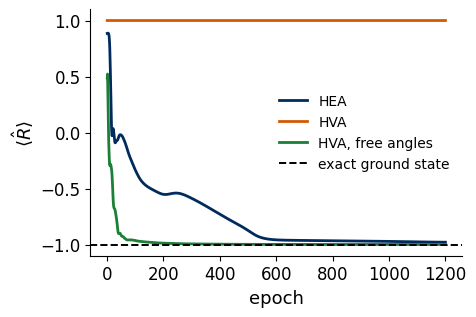

In [8]:
assert np.allclose(R @ R, np.eye(2 ** N)) and np.allclose(R @ H @ R, H, atol=TOL)
r_gs = ev(R, gs)
print(f"<R> in the exact ground state: {r_gs:+.6f}")
assert abs(r_gs + 1) < TOL                                                   # the ground state is mirror-odd

rng = np.random.default_rng(5)
for trial in range(5):                                                       # HVA states at random angles in [-pi, pi)
    p = np.asarray(state_hva(jnp.array(rng.uniform(-np.pi, np.pi, (L, 8)))))
    assert abs(ev(R, p) - 1) < TOL and abs(np.vdot(gs, p)) < TOL             # equation (5): even, orthogonal to |psi_0>
p_hva = np.asarray(state_hva(CLASS["HVA"]["theta"]))
print(f"<R> in the trained HVA state: {ev(R, p_hva):+.6f},  |<psi_0|psi_HVA>|^2 = {abs(np.vdot(gs, p_hva)) ** 2:.1e}")
assert abs(ev(R, p_hva) - 1) < TOL

# lowest energy in the even sector: diagonalise H restricted to the eigenvectors of R with eigenvalue +1
w_R, V_R = np.linalg.eigh(R)
B_even = V_R[:, w_R > 0]
E0_even = np.linalg.eigvalsh(B_even.T @ H @ B_even)[0]
print(f"lowest mirror-even energy {E0_even:.4f} = E1 = {E1:.4f};  trained HVA energy {ev(H, p_hva):.4f}")
assert abs(E0_even - E1) < TOL and ev(H, p_hva) >= E0_even - TOL
for name, d in CLASS.items():                                                # equation (6) along every run
    assert np.all(d["hist"][:, 3] <= (1 - d["hist"][:, 4]) / 2 + TOL)
RESULTS["mirror"] = dict(R_ground_state=r_gs, R_hva_trained=ev(R, p_hva), E0_even=E0_even)

fig, ax = plt.subplots()
for name, d in CLASS.items():
    ax.plot(np.arange(1, STEPS + 1), d["hist"][:, 4], color=COL[name], lw=2, label=name)
ax.axhline(r_gs, color="black", ls="--", lw=1.4, label="exact ground state")
ax.set_xlabel("epoch"); ax.set_ylabel(r"$\langle\hat R\rangle$"); ax.set_ylim(-1.1, 1.1)
ax.legend(frameon=False, fontsize=10, loc="center right")
save(fig, "fig_lab070e_reflection"); plt.show()

The exact ground state has $\langle\hat R\rangle=-1$, it is mirror-odd, whereas every HVA state has $\langle\hat R\rangle=+1$. The figure shows the reflection expectation value during training. Both starts, $|0\dots0\rangle$ and the product state, are mirror-even, and the small random angles of the HEA and of the HVA with free angles break this symmetry only partly, so these two runs begin with $\langle\hat R\rangle$ between one half and one. Training moves both to $\langle\hat R\rangle\approx-1$, which by inequality (6) is necessary for a fidelity close to one. The shared-angle HVA stays at $+1$ for every angle. The lowest energy it could ever reach is the lowest mirror-even eigenvalue, which here equals the first excited energy $E_1$, and four layers do not reach even that value.

The lesson holds well beyond this chain. A symmetry built into an ansatz restricts it to one symmetry sector, which reduces the number of angles and helps training when the target lies in that sector. When the target lies in another sector, no depth and no optimiser can help. Before training, one should therefore determine the quantum numbers of the target, here the reflection eigenvalue, and check that the ansatz can reach them, for example by starting from a state of the right sector or by giving up the symmetry, as the HVA with free angles does.

## 8. Optional. Three random starts per ansatz

This section repeats the training of Section 5 with the random starts of seeds 0, 1 and 2 for every ansatz and keeps, for each ansatz, the start with the lowest final energy, as in the figures of the lecture. The cell compares the result with the recorded numbers of the lecture figures, which were produced by the same model, seeds and optimiser, and redraws both figures for the kept starts.

HEA               seed 0: E - E0 = 1.05e-01, F = 0.9676


HEA               seed 1: E - E0 = 1.21e-01, F = 0.9652


HEA               seed 2: E - E0 = 1.03e-01, F = 0.9683


HVA               seed 0: E - E0 = 1.65e+00, F = 0.0000


HVA               seed 1: E - E0 = 2.62e+00, F = 0.0000


HVA               seed 2: E - E0 = 1.40e+00, F = 0.0000


HVA, free angles  seed 0: E - E0 = 8.30e-03, F = 0.9981


HVA, free angles  seed 1: E - E0 = 1.02e-02, F = 0.9976


HVA, free angles  seed 2: E - E0 = 5.23e-02, F = 0.9850
nine trainings: 24.4 s
match | exact: E0=-10.6453 E1=-9.6847 gap=0.9606 mx=-0.2031 mz=-0.1447 cxx=-0.6070 S=1.0243 bits
match | HEA: n=80, rel.err=9.6e-03, F=0.9683, mx=-0.2076, cxx=-0.6129, S=1.0167
match | HVA: n=32, rel.err=1.3e-01, F=0.0000, mx=-0.2569, cxx=-0.4557, S=0.9798
match | HVA, free angles: n=148, rel.err=7.8e-04, F=0.9981, mx=-0.2032, cxx=-0.6078, S=1.0081


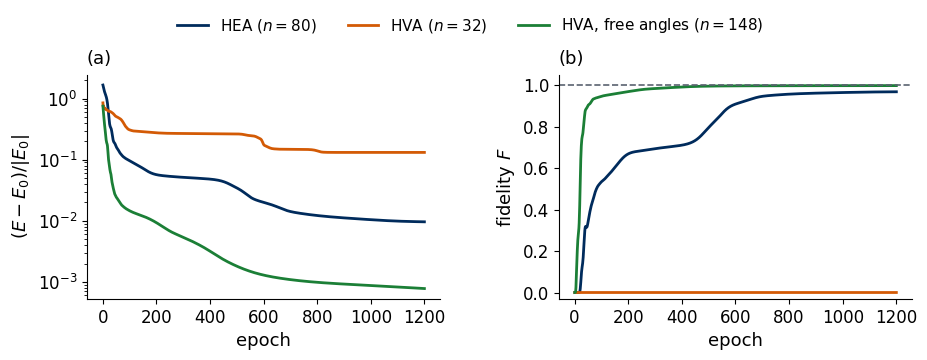

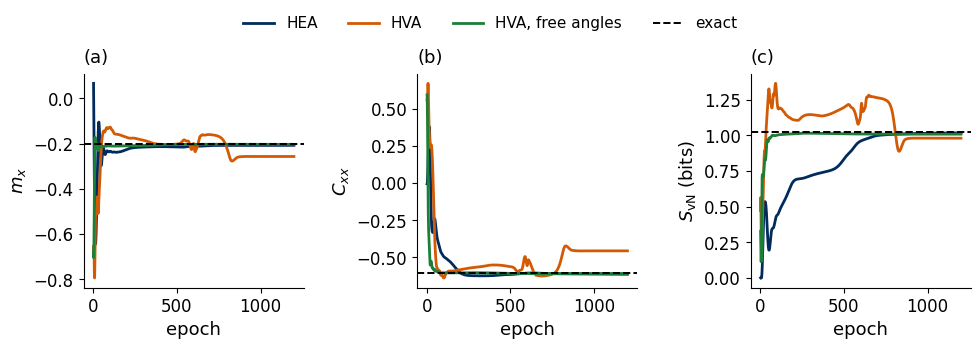

In [9]:
t0 = time.perf_counter()
BEST = {}
for name in STATE:
    for seed in range(3):
        th, rec, sch = TRAINERS[name](init(name, np.random.default_rng(seed)))
        h = history(rec, sch)
        print(f"{name:17s} seed {seed}: E - E0 = {h[-1, 0] - E0:.2e}, F = {h[-1, 3]:.4f}")
        if name not in BEST or h[-1, 0] < BEST[name][-1, 0]:
            BEST[name] = h
t_full = time.perf_counter() - t0
print(f"nine trainings: {t_full:.1f} s")
RESULTS["best_of_3"] = {name: dict(n=NPARAM[name], rel_err=(h[-1, 0] - E0) / abs(E0), F=h[-1, 3], mx=h[-1, 1],
                                   cxx=h[-1, 2], S=h[-1, 5]) for name, h in BEST.items()}

# the same lines as in beamer/figures/xyz_numbers.txt, written by make_xyz_example.py
lines = ["exact: E0=%.4f E1=%.4f gap=%.4f mx=%.4f mz=%.4f cxx=%.4f S=%.4f bits"
         % (E0, E1, E1 - E0, exact["mx"], ev(sum(Zs) / N, gs), exact["cxx"], exact["S"])]
for name, h in BEST.items():
    lines.append("%s: n=%d, rel.err=%.1e, F=%.4f, mx=%.4f, cxx=%.4f, S=%.4f"
                 % (name, NPARAM[name], (h[-1, 0] - E0) / abs(E0), h[-1, 3], h[-1, 1], h[-1, 2], h[-1, 5]))
recorded = Path("..") / "beamer" / "figures" / "xyz_numbers.txt"
if recorded.exists():
    old = recorded.read_text().splitlines()[1:]
    for new_line, old_line in zip(lines, old):
        print("match" if new_line == old_line else "DIFFERENT", "|", new_line)
    RESULTS["matches_recorded_numbers"] = lines == old
else:
    print("\n".join(lines))
plot_training(BEST, "fig_lab070e_training_best3")
plot_observables(BEST, "fig_lab070e_observables_best3")

The kept starts reproduce the numbers of the lecture figures to the printed digits. The spread between the three starts is small for the HEA and for the HVA with free angles, and for the shared-angle HVA every start ends with zero fidelity, as equation (5) demands. The kept HVA start ends with almost the exact half-chain entropy but with too weak correlations $C_{xx}$. A trial state can therefore carry the right amount of entanglement and still be orthogonal to the ground state, so the fidelity has to be checked besides the energy and the entropy.

In [10]:
RESULTS["runtime_classroom_training_seconds"] = t_class
RESULTS["runtime_optional_seconds"] = t_full
RESULTS["runtime_seconds"] = time.perf_counter() - started
(RES / "lab070e_results.json").write_text(json.dumps(RESULTS, indent=2, default=float))

def sci(x, digits=1):
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
B = RESULTS["best_of_3"]
NUMBERS = {"N": N, "L": L, "EZero": f"{E0:.4f}", "EOne": f"{E1:.4f}", "Gap": f"{E1 - E0:.3f}",
           "ExactMx": f"{exact['mx']:.3f}", "ExactCxx": f"{exact['cxx']:.3f}", "ExactS": f"{exact['S']:.2f}",
           "NHea": NPARAM["HEA"], "NHva": NPARAM["HVA"], "NFree": NPARAM["HVA, free angles"],
           "RelErrHea": sci(B["HEA"]["rel_err"]), "RelErrHva": sci(B["HVA"]["rel_err"]),
           "RelErrFree": sci(B["HVA, free angles"]["rel_err"]),
           "FidHea": f"{B['HEA']['F']:.3f}", "FidHva": f"{B['HVA']['F']:.3f}", "FidFree": f"{B['HVA, free angles']['F']:.3f}",
           "MirrorGs": f"{r_gs:+.0f}", "MirrorHva": f"{RESULTS['mirror']['R_hva_trained']:+.0f}",
           "EEven": f"{E0_even:.4f}", "Steps": STEPS, "Starts": 3, "Runtime": f"{RESULTS['runtime_seconds']:.0f}"}
with open(FIG / "nb_numbers_lab070e.tex", "w") as f:
    for key, val in NUMBERS.items():
        assert key.isalpha(), key
        f.write(f"\\newcommand{{\\labseventye{key}}}{{{val}}}\n")
print("numbers:", NUMBERS)
print(f"runtime of the whole notebook: {RESULTS['runtime_seconds']:.1f} s")

numbers: {'N': 8, 'L': 4, 'EZero': '-10.6453', 'EOne': '-9.6847', 'Gap': '0.961', 'ExactMx': '-0.203', 'ExactCxx': '-0.607', 'ExactS': '1.02', 'NHea': 80, 'NHva': 32, 'NFree': 148, 'RelErrHea': '9.6\\times10^{-3}', 'RelErrHva': '1.3\\times10^{-1}', 'RelErrFree': '7.8\\times10^{-4}', 'FidHea': '0.968', 'FidHva': '0.000', 'FidFree': '0.998', 'MirrorGs': '-1', 'MirrorHva': '+1', 'EEven': '-9.6847', 'Steps': 1200, 'Starts': 3, 'Runtime': '64'}
runtime of the whole notebook: 63.7 s


## 9. Exercises

1. Start the shared-angle HVA from a state without mirror symmetry, the product start with an additional $\hat R_y(\pi/2)$ on qubit 0 only. Follow $\langle\hat R\rangle$ and $F$ during training, explain with the argument of equation (5) why $\langle\hat R\rangle$ keeps its initial value for all angles, and compare the final fidelity with the bound (6).
2. Add a weak field $0.1\,\hat Z_0$ on the first qubit only. Show that $\hat R$ no longer commutes with $\hat{\mathcal H}$, retrain the three ansätze and compare the fidelity of the shared-angle HVA with Section 5.
3. Give the shared-angle HVA separate angles for the left and the right half of the chain, so that it has 16 angles per layer, and check with $\langle\hat R\rangle$ and $F$ which of its states are mirror-odd.
4. Train the three ansätze for $L=2,3,4,6$ and plot the final energy error against the number of angles $n$. Decide which ansatz uses its angles best.
5. Estimate, with equation (2), how many shots a device needs to measure $m_x$ of a trained state to an accuracy of $0.01$, using that the single-shot outcomes of $\hat X_i$ are $\pm1$.

## 10. Summary

On the open XYZ chain in two fields, a chain without conserved magnetisation or spin-flip parity, we compared three ansätze of four layers by their energy error, their fidelity with the exact ground state and three observables. The Hamiltonian-variational ansatz with a free angle for every gate prepared the ground state with a fidelity close to one, and the hardware-efficient ansatz came within a few percent. The Hamiltonian-variational ansatz with angles shared in each layer reached a much larger energy error and stayed orthogonal to the ground state at every epoch. Its gates and its start are symmetric under the reflection of the chain, so all its states are mirror-even, whereas the ground state is mirror-odd. An ansatz with a built-in symmetry can only reach targets in its own symmetry sector, and the quantum numbers of the target have to be checked before the circuit is chosen. During training, local observables settled before the half-chain entanglement, and a state with the correct entanglement could still be orthogonal to the ground state. All energies, gradients and fidelities were computed exactly from the state vector, whereas a device would estimate them from measured bit strings.

## References

[1] A. Peruzzo, J. McClean, P. Shadbolt, M.-H. Yung, X.-Q. Zhou, P. J. Love, A. Aspuru-Guzik, and J. L. O'Brien, A variational eigenvalue solver on a photonic quantum processor, Nat. Commun. **5**, 4213 (2014), [doi:10.1038/ncomms5213](https://doi.org/10.1038/ncomms5213).

[2] J. R. McClean, J. Romero, R. Babbush, and A. Aspuru-Guzik, The theory of variational hybrid quantum-classical algorithms, New J. Phys. **18**, 023023 (2016), [doi:10.1088/1367-2630/18/2/023023](https://doi.org/10.1088/1367-2630/18/2/023023).

[3] A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow, and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), [doi:10.1038/nature23879](https://doi.org/10.1038/nature23879).

[4] D. Wecker, M. B. Hastings, and M. Troyer, Progress towards practical quantum variational algorithms, Phys. Rev. A **92**, 042303 (2015), [doi:10.1103/PhysRevA.92.042303](https://doi.org/10.1103/PhysRevA.92.042303).

[5] D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).